# LunarLander pilot: normalization, overestimation and learning

This is an **executed exploratory pilot**, not the final course report. It uses
12 trained agents: DDPG and TD3, with/without critic LayerNorm, and three training
seeds per condition. Each agent collected 50,000 transitions.

You will learn how to read Q-value errors, understand layer normalization,
compare measured learning curves, and recognize the limits of a small experiment.
Read the explanation, then its output. **Run All only analyses saved data; it does
not start training.** Use **Python (miniproject1-DDPG)**. The live team report remains
on [Samskrift](https://samskrift.com/project/7ce99927-c689-46cf-b78a-6ea0d8ecc0d8).

In [1]:
from pathlib import Path
import json
import numpy as np
import torch
from IPython.display import display, Markdown, Image

from lunarlander_rl.paths import project_root

WORKSPACE = project_root()
from lunarlander_rl.experiment import discounted_returns
from lunarlander_rl.analyse import load_pilot, summaries, paired_effects, make_figures, write_analysis

RUN_ROOT = WORKSPACE / "./outputs/pilot-20261005"
FIG_ROOT = WORKSPACE / "generated/lunarlander-pilot-20261005"
manifest, runs = load_pilot(RUN_ROOT)
make_figures(runs, FIG_ROOT)
rows, effects = write_analysis(runs, FIG_ROOT)
print(f"Loaded {len(runs)} complete runs; training seeds {manifest['seeds']}.")
print("Versions:", json.loads((runs[0]['directory']/"metadata.json").read_text())['versions'])
print("Pilot settings:", manifest['config'])


Loaded 12 complete runs; training seeds [0, 1, 2].
Versions: {'rl-mind': '0.3.0', 'gymnasium': '1.3.0', 'torch': '2.14.0', 'numpy': '2.4.6', 'Box2D': '2.3.10'}
Pilot settings: {'max_steps': 50000, 'actor_hidden': [128, 128], 'critic_hidden': [128, 128], 'gamma': 0.99, 'tau': 0.005, 'actor_lr': 0.0003, 'critic_lr': 0.0003, 'batch_size': 128, 'replay_capacity': 100000, 'learning_starts': 5000, 'gradient_steps_per_transition': 1, 'exploration_noise': 0.1, 'policy_delay': 2, 'target_noise': 0.2, 'target_noise_clip': 0.5, 'eval_interval': 10000, 'eval_episodes': 10, 'eval_seed_start': 10000, 'train_horizon': 1000, 'diagnostic_horizon': 5000, 'diagnostic_stride': 10}


## 1. What is overestimation?

An actor chooses an action. Its critic predicts the discounted future reward
`Q(s,a)` after taking that action and following the current actor thereafter.
We freeze the actor and compare that prediction to observed future rewards:

\[
G_t = r_{t+1}+\gamma r_{t+2}+\gamma^2 r_{t+3}+\cdots,
\qquad e_t = Q(s_t,a_t)-G_t.
\]

Positive error means optimism; negative error means pessimism. Q does not have
to be positive to be optimistic: predicting -30 when the return is -100 is
an overestimate of +70. The average signed error estimates calibration on the
sampled visited pairs. A mean near zero can hide large positive and negative
errors, so we also report mean episode RMSE.

The next example is a **hand calculation**, not a LunarLander result.

In [2]:
example = discounted_returns([1, 2, 3], gamma=.5)
np.testing.assert_allclose(example, [2.75, 3.5, 3.])
print("Returns-to-go:", example)
print("If Q at the first pair is 3.75, signed error is", 3.75-example[0])


Returns-to-go: [2.75 3.5  3.  ]
If Q at the first pair is 3.75, signed error is 1.0


## 2. What does layer normalization change?

At a critic hidden layer, LayerNorm centers and scales its features **within
each sample**, then applies learned scale/offset parameters. Here it is placed
between the linear layer and ReLU, in both critic hidden layers. It does not use
minibatch statistics or running averages. The actor and critic output layer
remain unchanged. See the [Layer Normalization paper](https://arxiv.org/abs/1607.06450).

This can change optimization and the Q surface used by the actor. It is a
hypothesis that it improves calibration, not a guarantee. We need measurements.
The four conditions match architecture, learning rates, exploration, interaction
budget and seeds. Both algorithms use target actors. TD3 additionally has twin
critics, minimum targets, target smoothing and delayed actor/target updates.

The next check verifies a concrete control: paired conditions start with exactly
the same actor parameters.

In [3]:
for algorithm in ("ddpg", "td3"):
    for seed in manifest['seeds']:
        off = torch.load(RUN_ROOT/f"{algorithm}-ln0-seed{seed}/checkpoint-0000000.pt",
                         map_location='cpu', weights_only=True)['actor']
        on = torch.load(RUN_ROOT/f"{algorithm}-ln1-seed{seed}/checkpoint-0000000.pt",
                        map_location='cpu', weights_only=True)['actor']
        assert all(torch.equal(off[key], on[key]) for key in off)
print("Matched initial actors for every on/off seed pair: OK")


Matched initial actors for every on/off seed pair: OK


## 3. Read the learning curves

Higher return is better. Evaluation uses ten separate, fixed initial seeds and
no exploration noise, with a 1,000-step performance limit. Each thin line is
one trained agent; bold lines are condition means. Bands are **± one sample
standard deviation across three training seeds**, not a confidence interval.
The dashed 200-point line is a reference from the
[LunarLander documentation](https://gymnasium.farama.org/environments/box2d/lunar_lander/).

Read both learning speed and stability. A temporary good checkpoint can later
collapse. Our predefined final comparison uses 50,000 steps, not the best
checkpoint selected after looking at the curve.

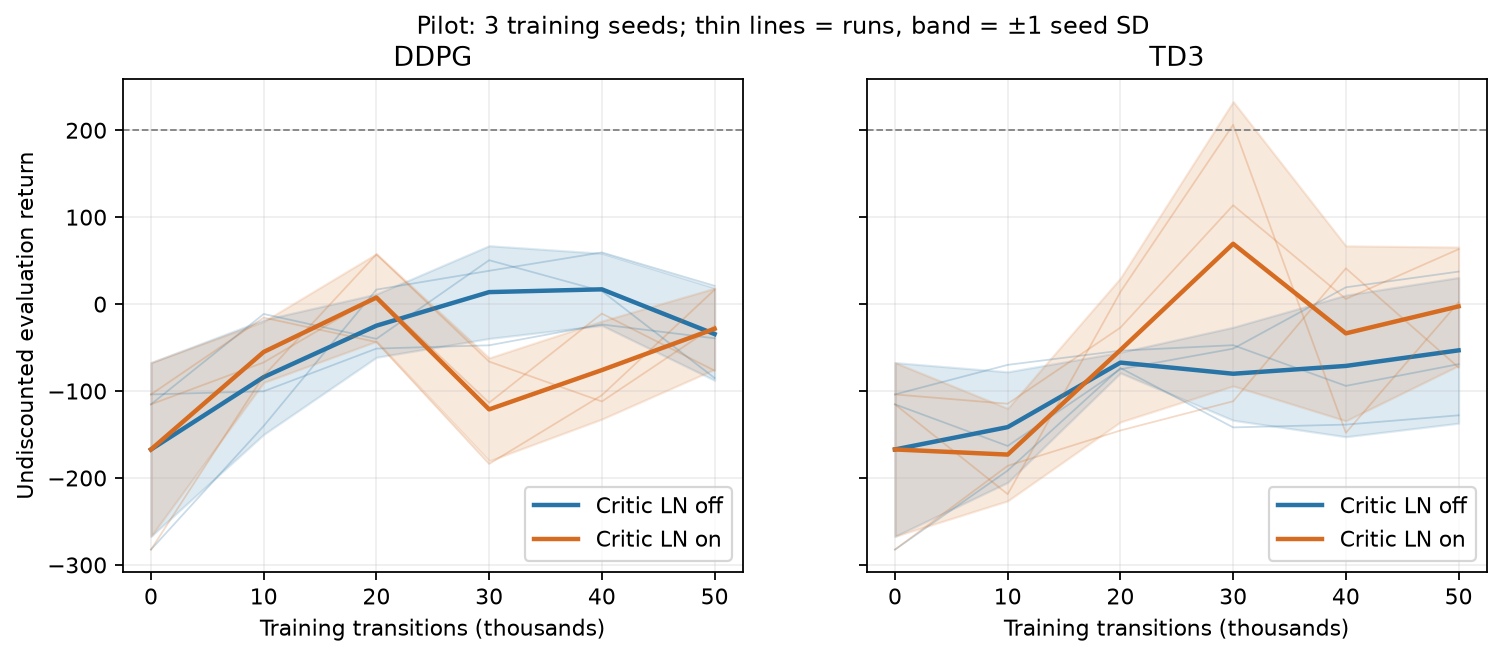

In [4]:
display(Image(filename=str(FIG_ROOT/"learning_curves.png")))


## 4. Why the time limit needed an audit

The critic bootstraps through artificial truncation and estimates continuing
value. Stopping a Monte Carlo rollout at 1,000 steps can omit its future tail.
Comparing these quantities without handling that tail would mislabel the missing
rewards as critic error.

We initially continued diagnostics to 5,000 steps and kept only naturally
terminated trajectories. Some policies kept hovering. Dropping them selects
completed trajectories, so we added a supplemental final-checkpoint audit:
**keep every episode**, roll it to natural termination or 10,000 steps, and
compare 2,500-, 5,000- and 10,000-step return estimates from the same trajectory.
Only pairs in the first 1,000 steps are sampled.

Naturally terminated trajectories give full observed MC returns. Censored ones
give finite approximations, clearly labeled. No Q estimate fills the tail.
The following result measures sensitivity on these observed rollouts; it is
not a proof bounding every possible future reward.

In [5]:
censored_original = sum(r['metrics'][-1]['diagnostic_censored'] for r in runs)
censored_long = sum(r['long']['censored_10000'] for r in runs)
delta25 = max(r['long']['delta_2500_5000_max'] for r in runs)
delta50 = max(r['long']['delta_5000_10000_max'] for r in runs)
print(f"Final original diagnostic: {censored_original}/120 episodes censored and excluded.")
print(f"Final supplemental diagnostic: {censored_long}/120 still censored, all retained.")
print(f"Largest observed 2500→5000 return change: {delta25:.9g}")
print(f"Largest observed 5000→10000 return change: {delta50:.9g}")
assert delta25 < 1e-3 and delta50 < 1e-3  # observed sensitivity for THIS dataset


Final original diagnostic: 23/120 episodes censored and excluded.
Final supplemental diagnostic: 23/120 still censored, all retained.
Largest observed 2500→5000 return change: 8.06096014e-06
Largest observed 5000→10000 return change: 0


## 5. Final scores and calibration

The table aggregates sampled pairs within episodes, then episodes within each
training run, then the three training runs. The seed is the inferential unit;
trajectory pairs are correlated repeated measurements. **Performance is
undiscounted reward; calibration uses gamma=.99 discounted returns.**

A larger signed error means more optimism. A smaller signed error may simply
mean more pessimism. Read RMSE alongside signed error. The RMSE entry averages
within-episode RMSE across episodes and then runs; it is not one pooled RMSE.
The learning-curve area is divided by the 50,000-step budget and captures
sample efficiency over the pilot, not just its endpoint.

In [6]:
table = ["| Algorithm | Critic LN | Final return | Signed Q1 error | Mean episode RMSE |",
         "|---|---|---:|---:|---:|"]
for row in rows:
    table.append(f"| {row['algorithm'].upper()} | {'on' if row['layer_norm'] else 'off'} | "
                 f"{row['return_mean']:.1f} ± {row['return_sd']:.1f} | "
                 f"{row['bias_q1_mean']:.1f} ± {row['bias_q1_sd']:.1f} | "
                 f"{row['rmse_q1_mean']:.1f} ± {row['rmse_q1_sd']:.1f} |")
display(Markdown("\n".join(table)))


| Algorithm | Critic LN | Final return | Signed Q1 error | Mean episode RMSE |
|---|---|---:|---:|---:|
| DDPG | off | -34.5 ± 53.2 | 92.4 ± 22.6 | 94.3 ± 22.5 |
| DDPG | on | -28.4 ± 46.6 | 121.2 ± 10.8 | 124.0 ± 11.9 |
| TD3 | off | -53.2 ± 83.8 | 18.8 ± 15.5 | 36.5 ± 8.2 |
| TD3 | on | -2.6 ± 68.2 | 10.3 ± 17.8 | 34.9 ± 1.4 |

## 6. Did normalization help? Compare paired changes

Subtract each seed's LN-off score from that same seed's LN-on score. This keeps
seed matching in the comparison. For return, a positive difference is better.
For signed error, a positive difference means more optimism; inspect RMSE to
assess overall calibration. The points below are the three individual changes;
black marks show their mean ± one sample SD. These are not significance tests.

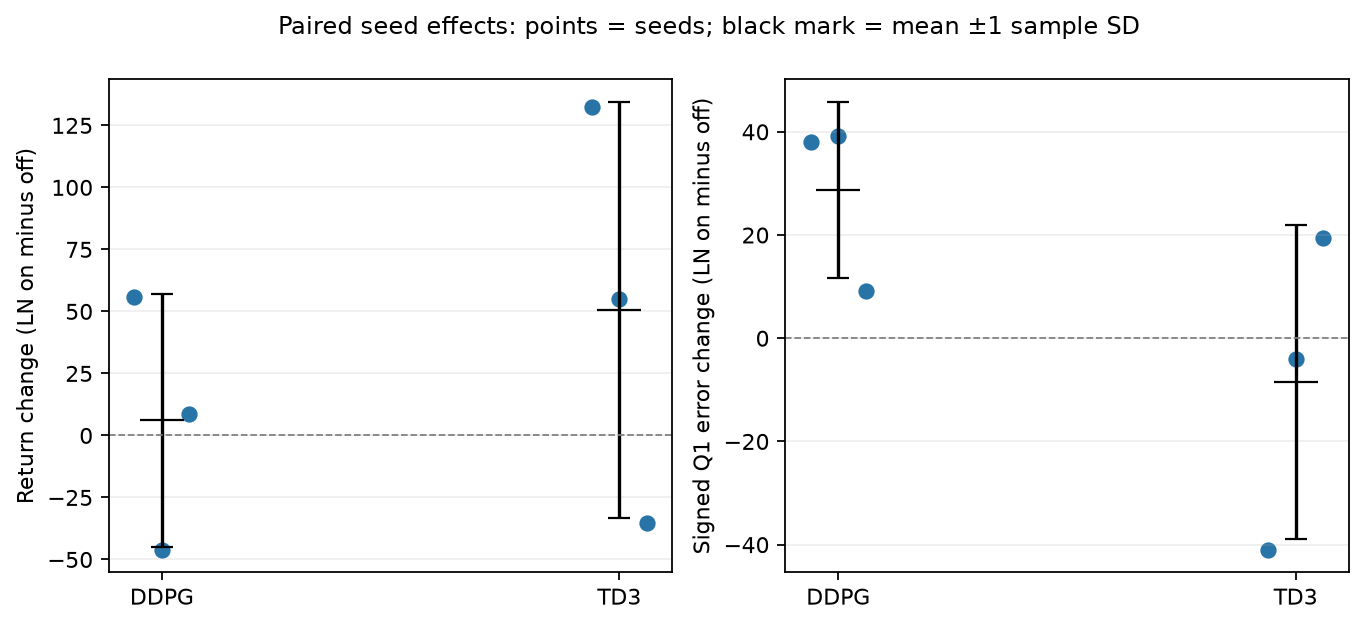

DDPG
  eval_return: mean change +6.1; individual changes [ 55.9 -46.1   8.5]
  bias_q1: mean change +28.8; individual changes [38.  39.2  9.1]
  rmse_q1: mean change +29.7; individual changes [39.  39.8 10.4]
TD3
  eval_return: mean change +50.6; individual changes [132.2  55.  -35.4]
  bias_q1: mean change -8.5; individual changes [-41.   -4.   19.5]
  rmse_q1: mean change -1.6; individual changes [-9.3  6.7 -2. ]


In [7]:
display(Image(filename=str(FIG_ROOT/"paired_effects.png")))
for algorithm in ("ddpg", "td3"):
    print(algorithm.upper())
    for metric in ("eval_return", "bias_q1", "rmse_q1"):
        item = next(e for e in effects if e['algorithm']==algorithm and e['metric']==metric)
        print(f"  {metric}: mean change {item['mean_difference']:+.1f}; "
              f"individual changes {np.round(item['seed_differences'], 1)}")


### Interpretation of this pilot

**DDPG:** LayerNorm raises signed Q error and mean episode RMSE in all three
paired seeds. Its average final return changes little relative to seed spread,
and its average learning-curve area is worse. This pilot does not support the
claim that critic normalization always reduces overestimation.

**TD3:** LayerNorm improves average final return, but one of the three paired
seeds gets worse. Average signed error decreases, but it increases in one seed.
Mean episode RMSE changes only slightly on average. That is a promising pattern
to investigate, with substantial uncertainty, not a statistically established
benefit.

**Across algorithms:** TD3 has much smaller critic errors here. Nevertheless,
TD3 without normalization has a worse average final return than DDPG without
normalization. An accurate critic can accurately evaluate a poor policy.
Smaller value errors alone do not guarantee stronger performance.

## 7. Inspect Q and return directly

Each point uses the prediction and return for the **same** state/action pair
under that checkpoint's frozen actor. Above the diagonal is optimism; below is
pessimism. DDPG's cloud is much more optimistic here. These thousands of points
are not thousands of independent agents and must not be used as the sample
size of an algorithm comparison.

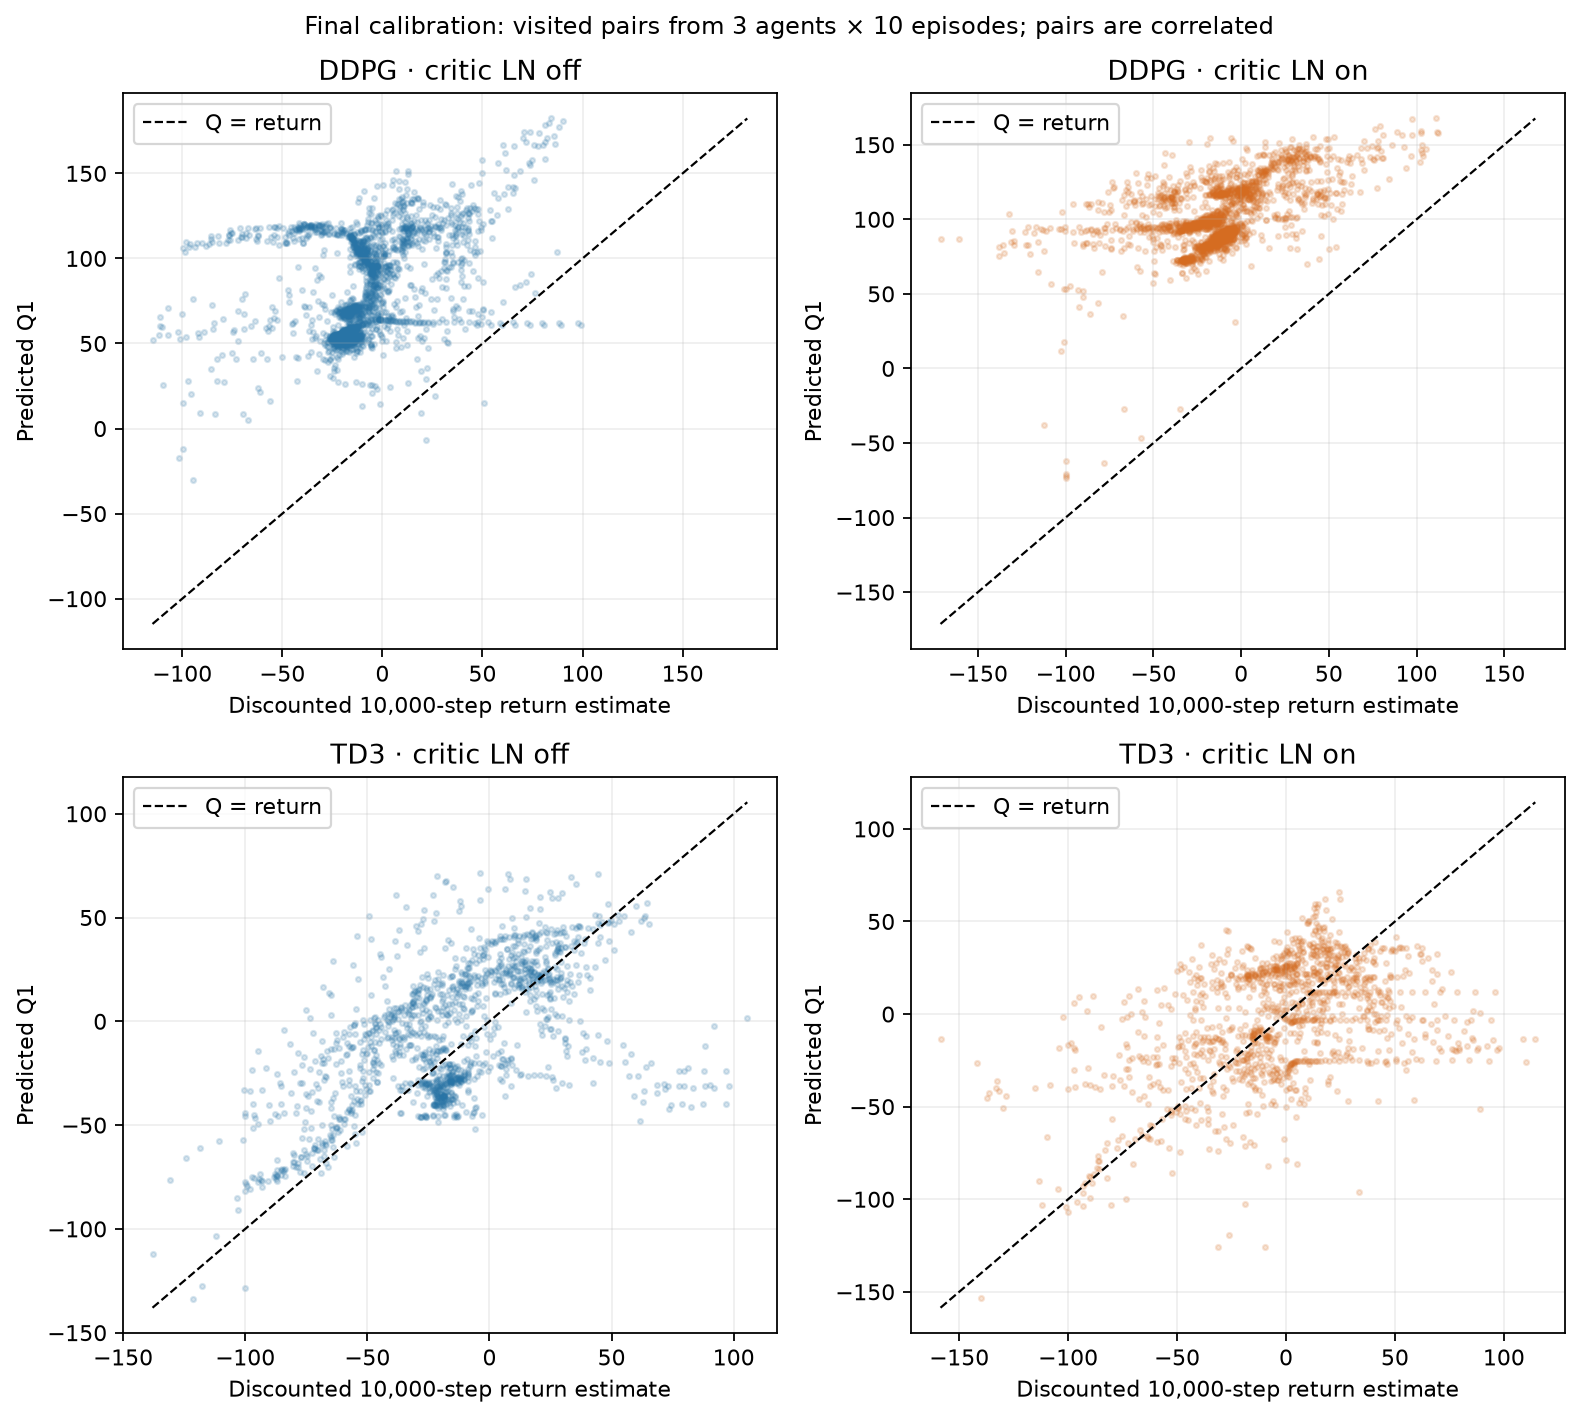

In [8]:
display(Image(filename=str(FIG_ROOT/"calibration.png")))


## 8. Does overestimation cause poor performance?

The scatter plot gives one point per final trained agent. It helps explore
whether error and performance move together. It cannot establish causation:
normalization changes optimization and actions, algorithms change several
mechanisms, and each policy visits a different state distribution.

Also avoid pooling all checkpoints into a correlation: both quantities change
with training time and checkpoints from one run are dependent. A later focused
TD3 minimum-versus-mean target ablation can narrow the mechanistic question,
but should still be interpreted as an intervention on the learning algorithm.

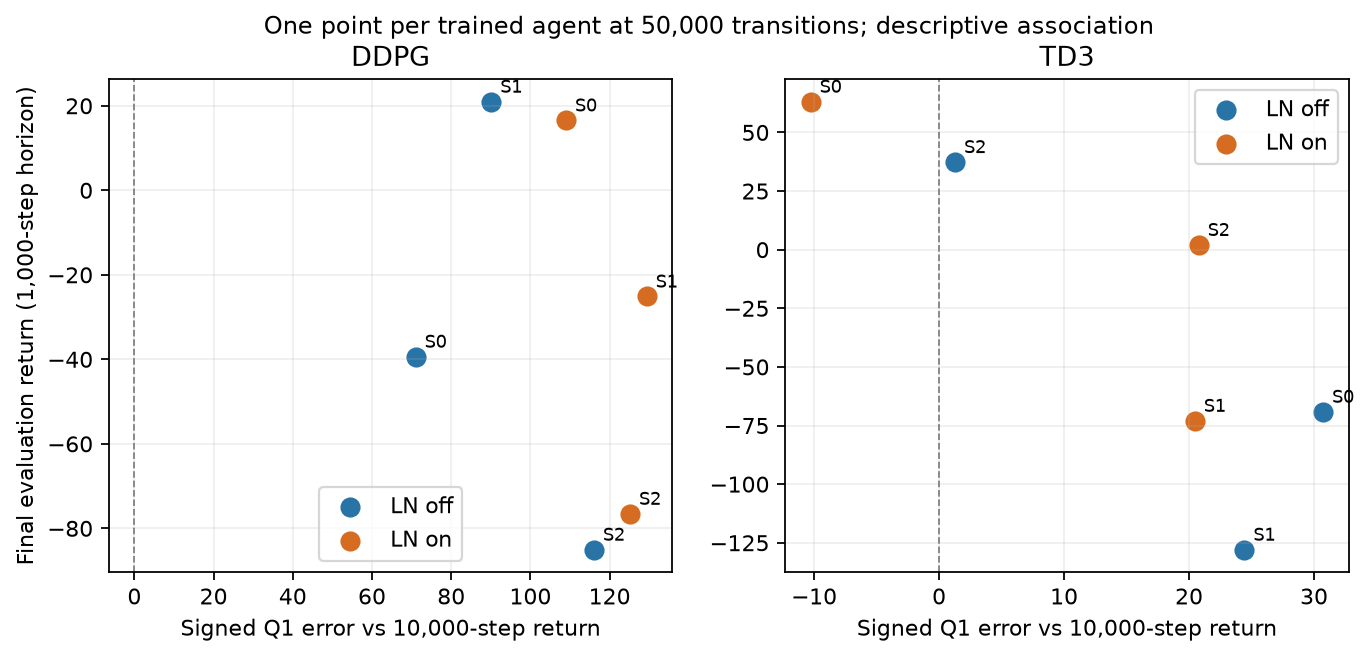

In [9]:
display(Image(filename=str(FIG_ROOT/"bias_vs_performance.png")))


## 9. What should we do next?

1. **Get beyond early learning.** Pilot a longer budget (roughly 300,000–500,000
   transitions) before freezing the main study. The current condition means
   remain below 200 and the curves are not uniformly stable.
2. **Keep the same four conditions.** Preserve the two-layer networks and
   matched settings initially. Do not start a broad Optuna search.
3. **Freeze settings, then collect fresh seeds.** Prefer 8–10 training seeds
   per condition and held-out evaluation initial seeds. Do not treat this tuned
   pilot as part of a confirmatory final sample.
4. **Measure error at early, middle and late checkpoints.** Use the improved
   horizon-sensitive diagnostic throughout. Include signed error, RMSE,
   performance and censoring. A seeded-prefix common-pair probe set can help
   separate state-visitation changes from calibration changes.
5. **Add one focused ablation if needed.** A TD3 minimum-versus-mean target
   comparison is more informative about pessimistic targets than simultaneously
   changing depth, update ratio, actor delay and normalization.

For the report: explain the two research questions, experimental controls,
matched-return measurement, all hyperparameters, uncertainty across seeds,
learning curves, calibration and limitations. Claim only what the actual final
sample supports. The pilot protocol and source code already provide a starting
point for reproducibility.

## Appendix: the original complete-only bias curves

These checkpoint curves exclude episodes that had not naturally ended by 5,000
steps, so they can suffer selection bias. They are retained to document the
measurement issue. **Use the supplemental all-trajectory diagnostics for the
main final comparison**, not these curves alone. The future study should apply
horizon sensitivity at all checkpoints.

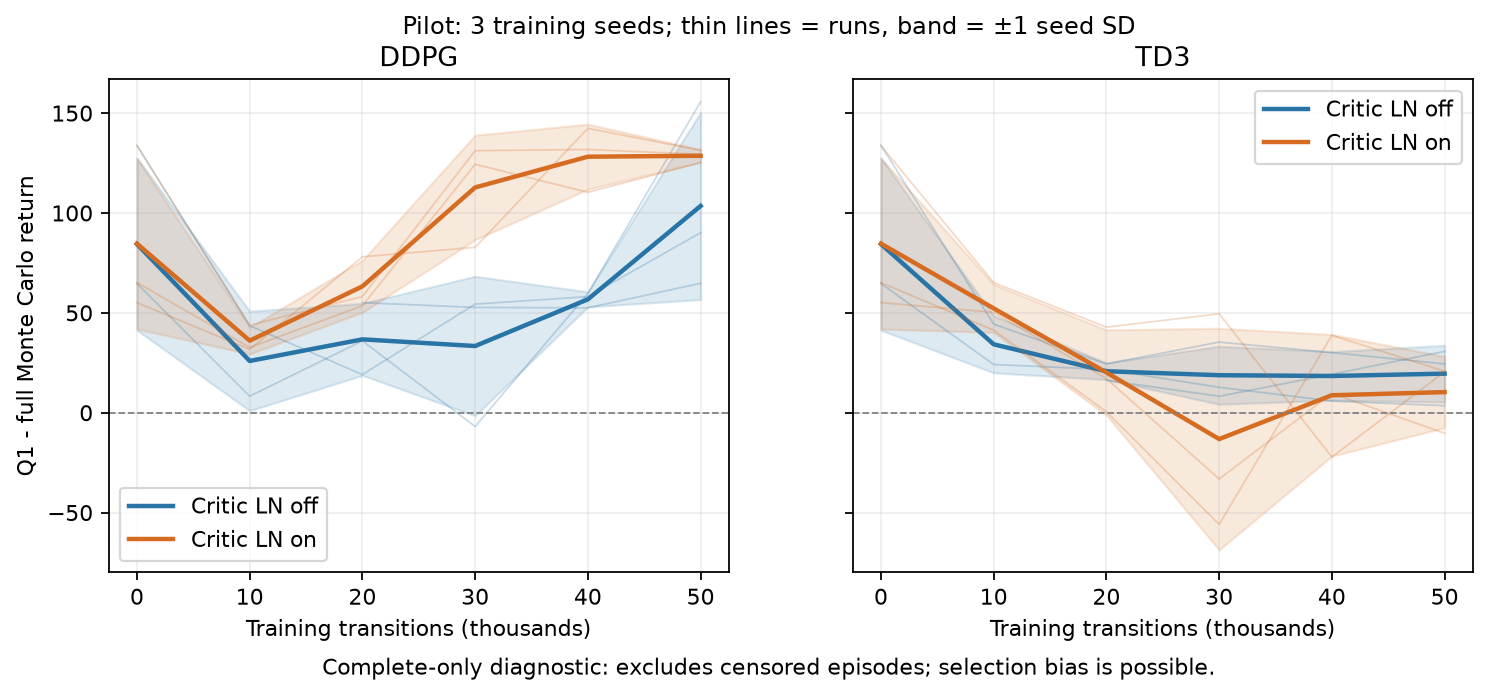

In [10]:
display(Image(filename=str(FIG_ROOT/"bias_curves_complete_only.png")))
